[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nahuelcostac/generative-networks/blob/main/diffusion/stable_diffusion.ipynb)

This notebook is part of the [Generative Networks course](https://www.nahuelcosta.com/teaching/generative-networks).

# Stable Diffusion, Piece by Piece

`diffusion.ipynb` trains a small diffusion model on MNIST. Stable Diffusion is the same idea at scale, with two changes: the diffusion happens in the **latent space of a VAE**, not on pixels, and it is **guided by a text prompt**. Here we take a pretrained Stable Diffusion 1.5 apart and look at the inputs and outputs of each piece:

1. The whole pipeline in one call.
2. The **VAE**: from 512 × 512 × 3 pixels to a 64 × 64 × 4 latent, and back.
3. The **text encoder** (CLIP's): from the prompt to one vector per token, $c$.
4. The **scheduler**: the same $\bar\alpha_t$ as in DDPM.
5. One call to the **U-Net**: $(z_t, t, c) \to \epsilon_\theta(z_t, t, c)$.
6. The generation loop written by hand, with classifier-free guidance.
7. One training step: only the U-Net learns.
8. Image to image: starting from a noised real latent.
9. CLIP: images and captions in the same space.

## 0. Dependencies

In [1]:
# Install the packages used by this notebook.
# In Colab and many course environments these are already installed, so this cell usually just prints a confirmation.
import importlib
from importlib.metadata import PackageNotFoundError, version
import subprocess
import sys

packages = [
    "torch",
    "torchvision",
    "matplotlib",
    "numpy",
    "diffusers",
    "transformers",
    "accelerate",
]

missing = []
for package in packages:
    try:
        version(package)
    except PackageNotFoundError:
        missing.append(package)

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

# A previous failed import may have cached this repository's transformers/ lesson folder
# as a namespace package. Clear only that mistaken module so Python finds the installed package.
importlib.invalidate_caches()
transformers_module = sys.modules.get("transformers")
if transformers_module is not None and getattr(transformers_module, "__file__", None) is None:
    del sys.modules["transformers"]

All required packages are already installed.


## 1. Setup

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.nn import functional as F
from torchvision.transforms.functional import to_pil_image, to_tensor

from diffusers import AutoencoderKL, DDIMScheduler, StableDiffusionPipeline, UNet2DConditionModel
from transformers import CLIPTextModel, CLIPTokenizer

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
dtype = torch.float16 if device.type == "cuda" else torch.float32
print(f"Using device: {device} ({dtype})")

model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
SEED = 42
prompt = "an axolotl surfing a wave"
num_steps = 50
guidance_scale = 7.5


def show_images(images, titles=None, size=3.0, cmap=None):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size + 0.4), squeeze=False)
    for i, image in enumerate(images):
        axes[0, i].imshow(image, cmap=cmap)
        axes[0, i].axis("off")
        if titles:
            axes[0, i].set_title(titles[i], fontsize=9)
    plt.tight_layout()
    plt.show()


def count_parameters(module):
    return sum(p.numel() for p in module.parameters())

Using device: cuda (torch.float16)


## 2. Load the Pieces

Stable Diffusion is three networks plus a scheduler. We load each one separately, so we can call them one by one.

In [3]:
load_kwargs = {"torch_dtype": dtype, "variant": "fp16"}
tokenizer = CLIPTokenizer.from_pretrained(model_id, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(model_id, subfolder="text_encoder", **load_kwargs).to(device)
unet = UNet2DConditionModel.from_pretrained(model_id, subfolder="unet", **load_kwargs).to(device)
vae = AutoencoderKL.from_pretrained(model_id, subfolder="vae", **load_kwargs).to(device)
scheduler = DDIMScheduler.from_pretrained(model_id, subfolder="scheduler")

for name, module in [("text encoder (CLIP)", text_encoder), ("U-Net", unet), ("VAE", vae)]:
    print(f"{name:>20}: {count_parameters(module) / 1e6:6.0f} M parameters")

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/home/nahuel/.conda/envs/generative-networks/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


 text encoder (CLIP):    123 M parameters
               U-Net:    860 M parameters
                 VAE:     84 M parameters


## 3. The Whole Pipeline in One Call

This is what a user of Stable Diffusion sees: a prompt in, an image out.

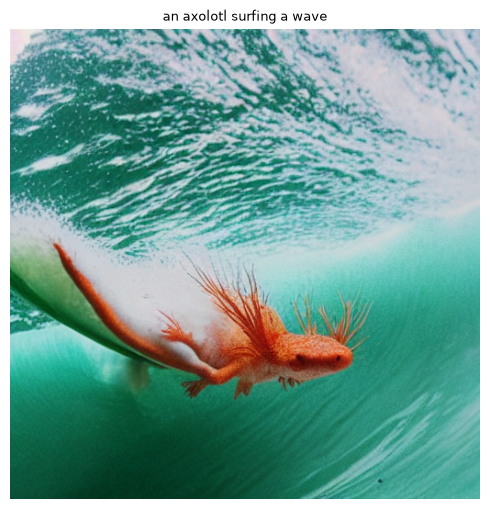

In [4]:
pipe = StableDiffusionPipeline(
    vae=vae, text_encoder=text_encoder, tokenizer=tokenizer, unet=unet, scheduler=scheduler,
    safety_checker=None, feature_extractor=None, requires_safety_checker=False,
)
pipe.set_progress_bar_config(disable=True)

generator = torch.Generator("cpu").manual_seed(SEED)
image = pipe(prompt, num_inference_steps=num_steps, guidance_scale=guidance_scale, generator=generator).images[0]
show_images([image], [prompt], size=5)

## 4. The VAE: Diffusion in the Latent Space

Running diffusion on pixels is expensive: the network has to go over every number of the image at every step. Stable Diffusion first compresses the image with the encoder of a VAE, runs the whole diffusion process on that latent, and only at the end decodes it back to pixels.

image:  (1, 3, 512, 512) -> 786,432 numbers
latent: (1, 4, 64, 64) -> 16,384 numbers (48 times fewer)
encoder's standard deviation, on average: 0.0004
latent: mean 0.25, std 0.86


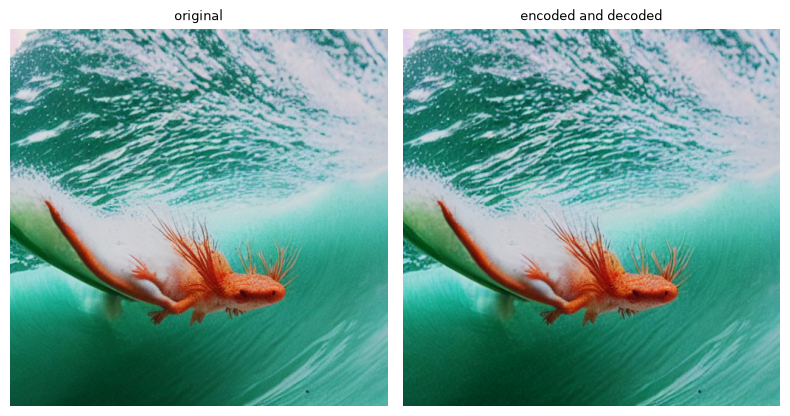

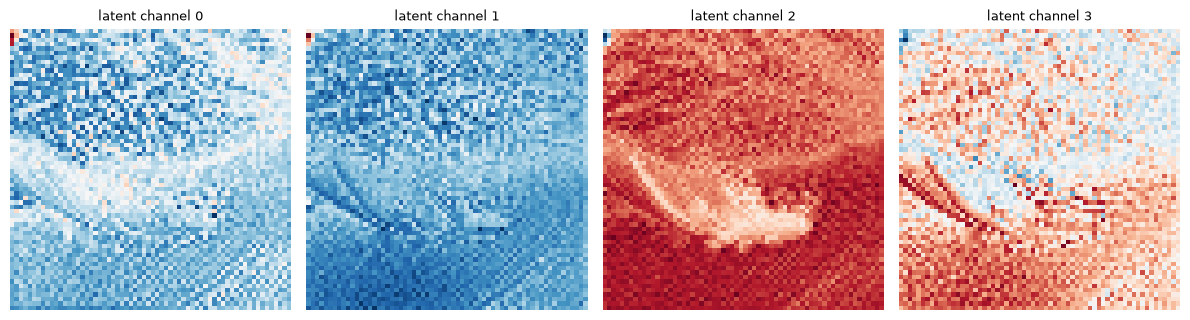

In [5]:
x = to_tensor(image).unsqueeze(0).to(device, dtype) * 2 - 1   # pixels in [-1, 1]
with torch.no_grad():
    posterior = vae.encode(x).latent_dist                      # a Gaussian, as in any VAE
    z_0 = posterior.mean * vae.config.scaling_factor           # the latent (scaled so its std is about 1)
    reconstruction = vae.decode(z_0 / vae.config.scaling_factor).sample

print(f"image:  {tuple(x.shape)} -> {x.numel():,} numbers")
print(f"latent: {tuple(z_0.shape)} -> {z_0.numel():,} numbers ({x.numel() / z_0.numel():.0f} times fewer)")
print(f"encoder's standard deviation, on average: {posterior.std.mean().item():.4f}")
print(f"latent: mean {z_0.mean().item():.2f}, std {z_0.std().item():.2f}")


def to_image(tensor):
    return to_pil_image(((tensor.float().cpu() + 1) / 2).clamp(0, 1))


show_images([image, to_image(reconstruction[0])], ["original", "encoded and decoded"], size=4)
show_images([z_0[0, i].float().cpu().numpy() for i in range(4)], [f"latent channel {i}" for i in range(4)], cmap="RdBu_r")

The four channels are not colours: they are features learned by the VAE. A decoder helper for the rest of the notebook:

In [6]:
@torch.no_grad()
def decode(latents):
    return [to_image(image) for image in vae.decode(latents / vae.config.scaling_factor).sample]

## 5. The Text Encoder: from Prompt to $c$

The prompt is split into tokens (always 77, padded) and CLIP's text encoder returns one vector per token: the sequence $c$ that the U-Net will read.

In [7]:
@torch.no_grad()
def encode_prompt(text):
    ids = tokenizer(text, padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt").input_ids
    return text_encoder(ids.to(device))[0]


ids = tokenizer(prompt, padding="max_length", max_length=tokenizer.model_max_length,
                truncation=True, return_tensors="pt").input_ids
print("token ids:", tuple(ids.shape))
print("tokens:   ", tokenizer.convert_ids_to_tokens(ids[0][:10]))
c = encode_prompt(prompt)
print("c:        ", tuple(c.shape))

token ids: (1, 77)
tokens:    ['<|startoftext|>', 'an</w>', 'ax', 'o', 'lot', 'l</w>', 'surfing</w>', 'a</w>', 'wave</w>', '<|endoftext|>']
c:         (1, 77, 768)


The output vectors take the context into account. The word "cat" has the same input embedding in any sentence, but its output vector changes with the words around it. One detail: CLIP's text encoder is *causal*, like a language model: each token only looks at the tokens before it. So "cat" changes when the words before it change, but not when the words after it do.

In [8]:
@torch.no_grad()
def word_vectors(sentence, word):
    ids = tokenizer(sentence, padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt").input_ids.to(device)
    position = tokenizer.convert_ids_to_tokens(ids[0]).index(word + "</w>")
    before = text_encoder.get_input_embeddings()(ids)[0, position].float()
    after = text_encoder(ids)[0][0, position].float()
    return before, after


for sentence_a, sentence_b in [("a surfing cat", "a sleeping cat"), ("a cat surfing a wave", "a cat sleeping on a sofa")]:
    before_a, after_a = word_vectors(sentence_a, "cat")
    before_b, after_b = word_vectors(sentence_b, "cat")
    print(f"'{sentence_a}' vs '{sentence_b}': 'cat' has cosine similarity "
          f"{F.cosine_similarity(before_a, before_b, dim=0).item():.3f} at the input and "
          f"{F.cosine_similarity(after_a, after_b, dim=0).item():.3f} at the output")

'a surfing cat' vs 'a sleeping cat': 'cat' has cosine similarity 1.000 at the input and 0.711 at the output
'a cat surfing a wave' vs 'a cat sleeping on a sofa': 'cat' has cosine similarity 1.000 at the input and 1.000 at the output


## 6. The Scheduler

The scheduler holds the $\beta_t$ and $\bar\alpha_t$ of the forward process, and knows how to take one reverse step. Stable Diffusion was trained with $T = 1000$ steps, like DDPM, but with a different schedule (`scaled_linear`, smaller $\beta$). Compare it with the DDPM schedule of `diffusion.ipynb`.

{'num_train_timesteps': 1000, 'beta_schedule': 'scaled_linear', 'beta_start': 0.00085, 'beta_end': 0.012}


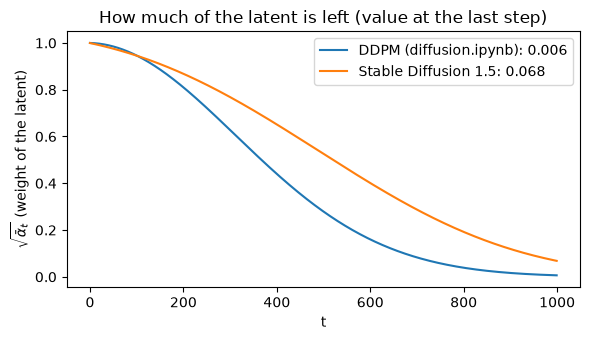

In [9]:
print({key: scheduler.config[key] for key in ["num_train_timesteps", "beta_schedule", "beta_start", "beta_end"]})

sd_alpha_bars = scheduler.alphas_cumprod.numpy()
ddpm_alpha_bars = torch.cumprod(1 - torch.linspace(1e-4, 0.02, 1000), dim=0).numpy()
plt.figure(figsize=(6, 3.5))
plt.plot(np.sqrt(ddpm_alpha_bars), label=f"DDPM (diffusion.ipynb): {np.sqrt(ddpm_alpha_bars[-1]):.3f}")
plt.plot(np.sqrt(sd_alpha_bars), label=f"Stable Diffusion 1.5: {np.sqrt(sd_alpha_bars[-1]):.3f}")
plt.xlabel("t")
plt.ylabel(r"$\sqrt{\bar\alpha_t}$ (weight of the latent)")
plt.title("How much of the latent is left (value at the last step)")
plt.legend()
plt.tight_layout()
plt.show()

Stable Diffusion 1.5 does not quite reach pure noise either: at its last step about 7 % of the latent is left. Lin et al. (2023), *Common Diffusion Noise Schedules and Sample Steps are Flawed*, showed that this keeps it from generating very bright or very dark images, the same mismatch between training and sampling as in section 18 of `diffusion.ipynb`, only milder.

The forward process in the latent space, decoded to pixels at each step:

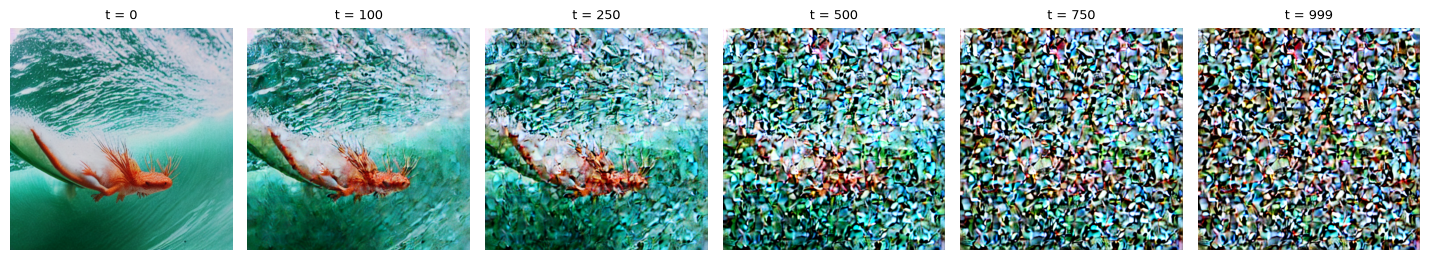

In [10]:
generator = torch.Generator("cpu").manual_seed(0)
noise = torch.randn(z_0.shape, generator=generator, dtype=dtype).to(device)
timesteps = [0, 100, 250, 500, 750, 999]
noisy_latents = torch.cat([scheduler.add_noise(z_0, noise, torch.tensor([t], device=device)) for t in timesteps])
show_images(decode(noisy_latents), [f"t = {t}" for t in timesteps], size=2.4)

## 7. One Call to the U-Net

The U-Net is the network that removes noise. It receives three things: the noisy latent $z_t$, the step $t$ and the text $c$; and it returns the predicted noise, the same size as the latent. The text enters through cross-attention: each region of the latent looks at the tokens of $c$ that matter to it.

z_t: (1, 4, 64, 64)   t: 500   c: (1, 77, 768)   ->   predicted noise: (1, 4, 64, 64)
squared error against the real noise: 0.1057


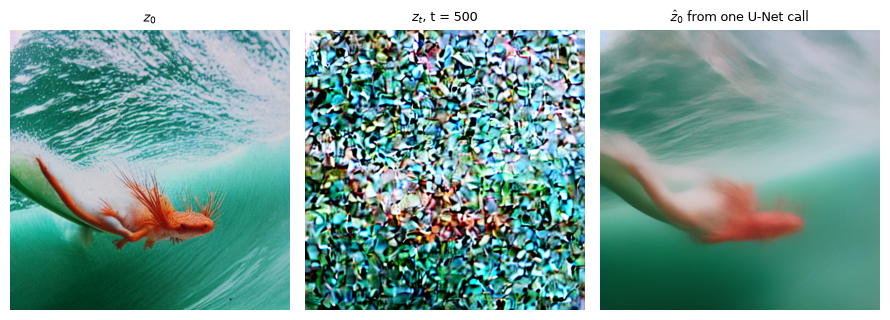

In [11]:
t = torch.tensor([500], device=device)
z_t = scheduler.add_noise(z_0, noise, t)
with torch.no_grad():
    predicted_noise = unet(z_t, t, encoder_hidden_states=c).sample

print(f"z_t: {tuple(z_t.shape)}   t: {t.item()}   c: {tuple(c.shape)}   ->   predicted noise: {tuple(predicted_noise.shape)}")
print(f"squared error against the real noise: {F.mse_loss(predicted_noise.float(), noise.float()).item():.4f}")

alpha_bar_t = scheduler.alphas_cumprod[t.item()].to(device, dtype)
z_0_guess = (z_t - (1 - alpha_bar_t).sqrt() * predicted_noise) / alpha_bar_t.sqrt()
show_images(decode(torch.cat([z_0, z_t, z_0_guess])), ["$z_0$", "$z_t$, t = 500", r"$\hat{z}_0$ from one U-Net call"], size=3)

## 8. The Generation Loop, by Hand

Everything the pipeline did in section 3, written out:

1. Encode the prompt into $c$, and the empty prompt into $c_\varnothing$ (for guidance).
2. Sample a pure-noise latent $z_T$.
3. At each step, call the U-Net twice (with $c$ and with $c_\varnothing$), combine both with classifier-free guidance, and let the scheduler compute $z_{t-1}$.
4. Decode $z_0$ with the VAE.

mean difference with the pipeline's image: 0.54 (out of 255)


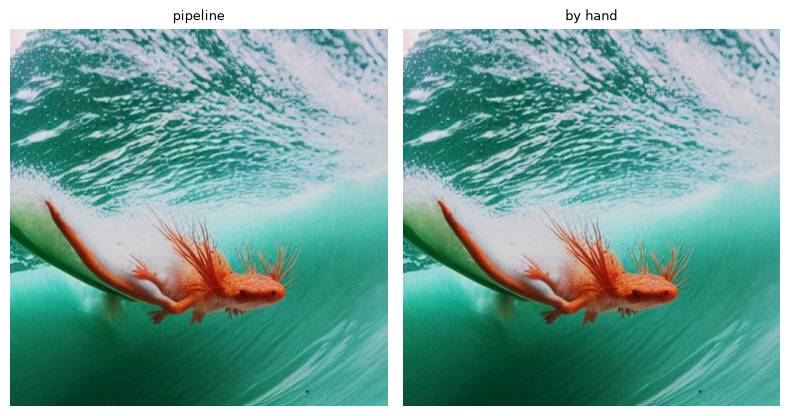

In [12]:
@torch.no_grad()
def denoise(latents, timesteps, c, c_empty, guidance_scale=guidance_scale, snapshots=None):
    for i, t in enumerate(timesteps):
        noise_empty, noise_text = unet(torch.cat([latents] * 2), t,
                                       encoder_hidden_states=torch.cat([c_empty, c])).sample.chunk(2)
        noise = noise_empty + guidance_scale * (noise_text - noise_empty)   # classifier-free guidance
        step = scheduler.step(noise, t, latents)
        if snapshots is not None and i % 10 == 0:
            snapshots.append((int(t), latents.clone(), step.pred_original_sample.clone()))
        latents = step.prev_sample
    return latents


@torch.no_grad()
def generate(prompt, seed=SEED, num_steps=num_steps, guidance_scale=guidance_scale, snapshots=None):
    c, c_empty = encode_prompt(prompt), encode_prompt("")
    scheduler.set_timesteps(num_steps)
    generator = torch.Generator("cpu").manual_seed(seed)
    latents = torch.randn((1, unet.config.in_channels, 64, 64), generator=generator, dtype=dtype).to(device)
    latents = latents * scheduler.init_noise_sigma
    return denoise(latents, scheduler.timesteps, c, c_empty, guidance_scale, snapshots)


snapshots = []
z_0_generated = generate(prompt, snapshots=snapshots)
by_hand = decode(z_0_generated)[0]
difference = np.abs(np.asarray(by_hand, dtype=float) - np.asarray(image, dtype=float)).mean()
print(f"mean difference with the pipeline's image: {difference:.2f} (out of 255)")
show_images([image, by_hand], ["pipeline", "by hand"], size=4)

The trajectory: the latent $z_t$ decoded at some steps (top) and the scheduler's guess of the final latent $\hat{z}_0$ at those steps (bottom).

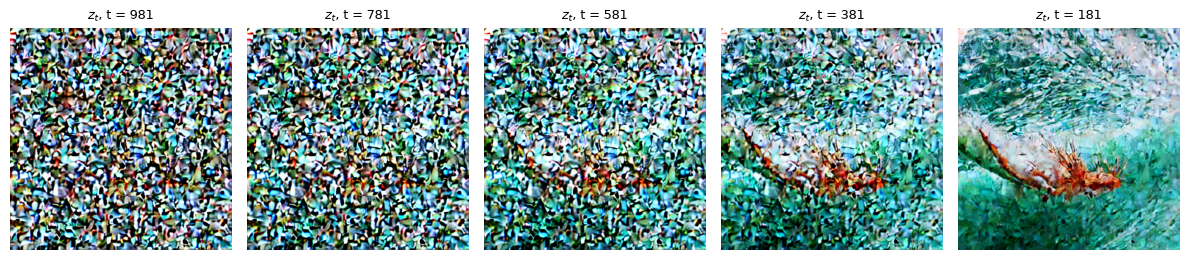

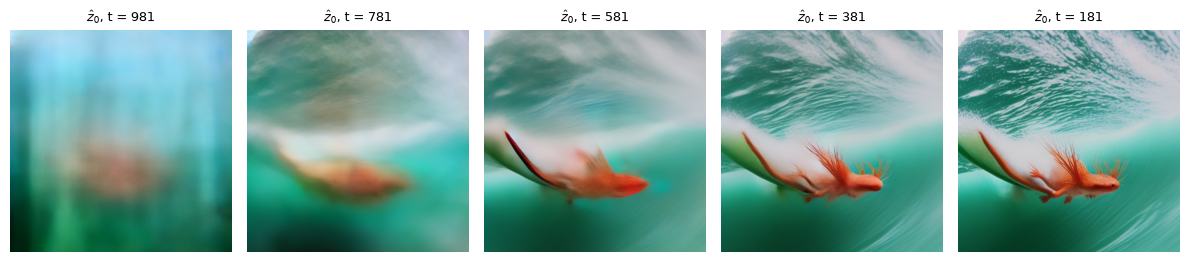

In [13]:
show_images(decode(torch.cat([z for _, z, _ in snapshots])), [f"$z_t$, t = {t}" for t, _, _ in snapshots], size=2.4)
show_images(decode(torch.cat([z for _, _, z in snapshots])), [r"$\hat{z}_0$" + f", t = {t}" for t, _, _ in snapshots], size=2.4)

### The guidance scale

The same seed with different $w$. With $w = 1$ there is no guidance, just conditioning on the text.

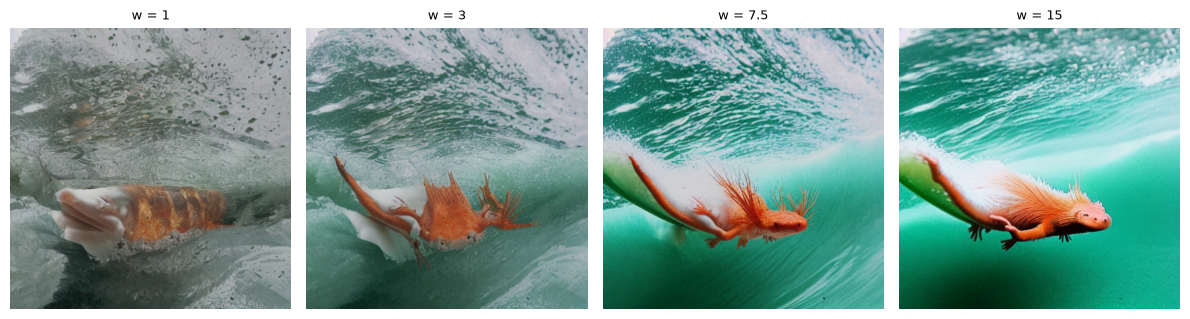

In [14]:
scales = [1.0, 3.0, 7.5, 15.0]
show_images([decode(generate(prompt, guidance_scale=w))[0] for w in scales], [f"w = {w:g}" for w in scales], size=3)

## 9. One Training Step

Training Stable Diffusion is the same loop as in `diffusion.ipynb`, in the latent space and with the text: encode the image into $z_0$ and its caption into $c$, pick a random step, add its noise, and ask the U-Net for it. The loss is the same $L_\text{simple}$:

$$L = \mathbb{E}_{z_0, \epsilon, t, c}\big[\lVert \epsilon - \epsilon_\theta(z_t, t, c) \rVert^2\big]$$

The VAE and CLIP come pretrained and stay frozen: only the U-Net learns. We compute one loss and one backward pass to see where the gradients go (we do not update anything).

In [15]:
vae.requires_grad_(False)
text_encoder.requires_grad_(False)
unet.requires_grad_(True)

generator = torch.Generator("cpu").manual_seed(1)
t = torch.randint(0, scheduler.config.num_train_timesteps, (1,), generator=generator).to(device)
noise = torch.randn(z_0.shape, generator=generator, dtype=dtype).to(device)
z_t = scheduler.add_noise(z_0, noise, t)

loss = F.mse_loss(unet(z_t, t, encoder_hidden_states=encode_prompt(prompt)).sample.float(), noise.float())
loss.backward()
print(f"t = {t.item()}, loss = {loss.item():.4f}")
for name, module in [("VAE", vae), ("text encoder", text_encoder), ("U-Net", unet)]:
    with_gradient = sum(p.numel() for p in module.parameters() if p.grad is not None)
    print(f"{name:>13}: {with_gradient / 1e6:6.0f} M of {count_parameters(module) / 1e6:4.0f} M parameters received a gradient")

unet.zero_grad(set_to_none=True)
unet.requires_grad_(False)

t = 845, loss = 0.0112
          VAE:      0 M of   84 M parameters received a gradient
 text encoder:      0 M of  123 M parameters received a gradient
        U-Net:    860 M of  860 M parameters received a gradient


UNet2DConditionModel(
  (conv_in): Conv2d(4, 320, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_proj): Timesteps()
  (time_embedding): TimestepEmbedding(
    (linear_1): Linear(in_features=320, out_features=1280, bias=True)
    (act): SiLU()
    (linear_2): Linear(in_features=1280, out_features=1280, bias=True)
  )
  (down_blocks): ModuleList(
    (0): CrossAttnDownBlock2D(
      (attentions): ModuleList(
        (0-1): 2 x Transformer2DModel(
          (norm): GroupNorm(32, 320, eps=1e-06, affine=True, bias=True)
          (proj_in): Conv2d(320, 320, kernel_size=(1, 1), stride=(1, 1))
          (transformer_blocks): ModuleList(
            (0): BasicTransformerBlock(
              (norm1): LayerNorm((320,), eps=1e-05, elementwise_affine=True, bias=True)
              (attn1): Attention(
                (to_q): Linear(in_features=320, out_features=320, bias=False)
                (to_k): Linear(in_features=320, out_features=320, bias=False)
                (to_v): Linear(i

## 10. Image to Image

As in section 16 of `diffusion.ipynb`: encode a real image, add the noise of an intermediate step, and run the rest of the reverse process, now with a different prompt. The `strength` is the fraction of the steps we go back: the higher, the more the model makes up.

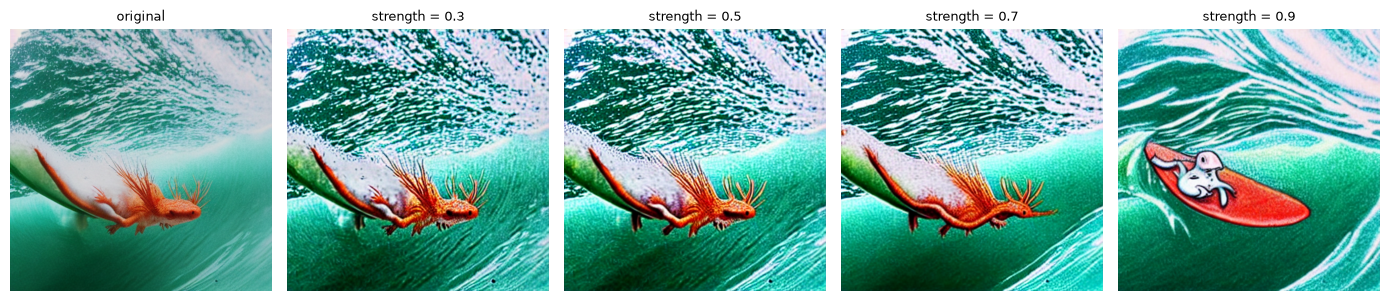

In [16]:
@torch.no_grad()
def image_to_image(image_latents, prompt, strength, seed=SEED, num_steps=num_steps):
    scheduler.set_timesteps(num_steps)
    timesteps = scheduler.timesteps[int(num_steps * (1 - strength)):]
    generator = torch.Generator("cpu").manual_seed(seed)
    noise = torch.randn(image_latents.shape, generator=generator, dtype=dtype).to(device)
    latents = scheduler.add_noise(image_latents, noise, timesteps[:1])
    return denoise(latents, timesteps, encode_prompt(prompt), encode_prompt(""))


new_prompt = "a pencil sketch of an axolotl surfing a wave"
strengths = [0.3, 0.5, 0.7, 0.9]
show_images([image] + [decode(image_to_image(z_0, new_prompt, s))[0] for s in strengths],
            ["original"] + [f"strength = {s}" for s in strengths], size=2.8)

## 11. CLIP: Images and Captions in the Same Space

Stable Diffusion only uses CLIP's text encoder, but CLIP was trained with two encoders, one for images and one for text, so that an image and its caption end up close together (contrastive learning). We generate four images, encode them and their captions with the full CLIP model, and compare all pairs with the cosine similarity. This cell downloads CLIP ViT-L/14 (about 1.7 GB).

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

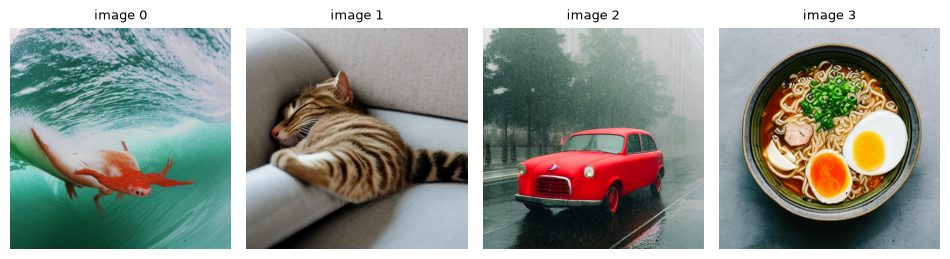

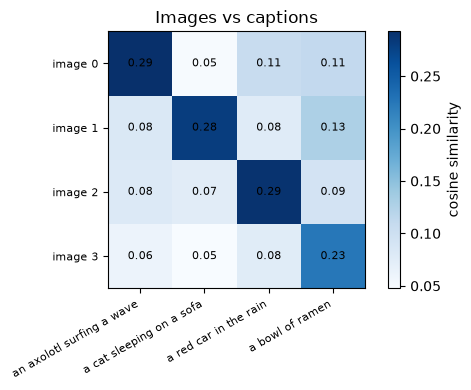

In [17]:
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-large-patch14", torch_dtype=dtype).to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-large-patch14")

captions = ["an axolotl surfing a wave", "a cat sleeping on a sofa", "a red car in the rain", "a bowl of ramen"]
images = [decode(generate(caption, num_steps=25))[0] for caption in captions]

inputs = processor(text=captions, images=images, return_tensors="pt", padding=True).to(device)
inputs["pixel_values"] = inputs["pixel_values"].to(dtype)
with torch.no_grad():
    outputs = clip(**inputs)
image_vectors = F.normalize(outputs.image_embeds.float(), dim=-1)
text_vectors = F.normalize(outputs.text_embeds.float(), dim=-1)
similarity = (image_vectors @ text_vectors.T).cpu().numpy()

show_images(images, [f"image {i}" for i in range(len(images))], size=2.4)
plt.figure(figsize=(5.5, 4))
plt.imshow(similarity, cmap="Blues")
plt.colorbar(label="cosine similarity")
plt.xticks(range(len(captions)), captions, rotation=30, ha="right", fontsize=8)
plt.yticks(range(len(images)), [f"image {i}" for i in range(len(images))], fontsize=8)
for i in range(len(images)):
    for j in range(len(captions)):
        plt.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Images vs captions")
plt.tight_layout()
plt.show()

Is Stable Diffusion's text encoder the same as the text half of this CLIP model? Compare the weights:

In [18]:
def text_weights(module):
    """The weights of the text encoder, with the same names in both models."""
    return {name.removeprefix("text_model."): weights for name, weights in module.state_dict().items()
            if name.startswith(("text_model.", "embeddings.", "encoder.", "final_layer_norm."))}


sd_weights, clip_weights = text_weights(text_encoder), text_weights(clip)
shared = sorted(sd_weights.keys() & clip_weights.keys())
max_difference = max((sd_weights[name].float() - clip_weights[name].float()).abs().max().item() for name in shared)
print(f"{len(shared)} of {len(sd_weights)} tensors in common; largest difference between them: {max_difference:.2e}")

196 of 196 tensors in common; largest difference between them: 0.00e+00


## 12. Things to Try

- Change the prompt, the seed and the number of steps. How few steps still give a good image with DDIM?
- Add a *negative prompt*: use its encoding instead of the empty prompt's $c_\varnothing$ in `denoise`.
- Decode $\hat{z}_0$ at every step of the loop to see when the composition is decided.
- Swap the scheduler (`DPMSolverMultistepScheduler`, `EulerDiscreteScheduler`) without touching the U-Net.